In [32]:
import os
NOTEBOOK_NAME = 'Training25ClassOutputs'
BASE_DIR = f'/mnt/d/Projects/SIBI Recognition Lecturers/Backend/notebooks/{NOTEBOOK_NAME}'
os.makedirs(BASE_DIR, exist_ok=True)
os.chdir(BASE_DIR)
print('Working directory sekarang:', os.getcwd())

Working directory sekarang: /mnt/d/Projects/SIBI Recognition Lecturers/Backend/notebooks/Training25ClassOutputs


In [33]:
%pip install -q numpy==1.26.4 tensorflow==2.17.0 matplotlib==3.9.4 scikit-learn==1.5.2 protobuf==4.25.3

Note: you may need to restart the kernel to use updated packages.


In [34]:
import os
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.utils.class_weight import compute_class_weight

from keras.utils import to_categorical
from keras.models import Model
from keras.layers import (
    Input, Dense, Dropout, BatchNormalization,
    Bidirectional, LSTM, Layer, GaussianNoise
)
from keras.optimizers import Adam
from keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint
from keras.regularizers import l2

# ====== KONFIGURASI EKSPERIMEN — UBAH DI SINI SAJA ======
import datetime

N_EPOCHS = 500
RUN_TIMESTAMP = datetime.datetime.now().strftime('%Y%m%d_%H%M%S')
PATH_CONFIGURATION_GENERAL = f'Epoch{N_EPOCHS}_{RUN_TIMESTAMP}'
os.makedirs(PATH_CONFIGURATION_GENERAL, exist_ok=True)
print(f'Output eksperimen ini akan disimpan ke folder: {PATH_CONFIGURATION_GENERAL}')
# ==========================================================

print(f'TensorFlow  : {tf.__version__}')
print(f'Keras       : {tf.keras.__version__}')
print(f'GPU tersedia: {tf.config.list_physical_devices("GPU")}')

Output eksperimen ini akan disimpan ke folder: Epoch500_20260915_161659
TensorFlow  : 2.17.0
Keras       : 3.12.4
GPU tersedia: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [35]:
DATA_PATH = '/mnt/d/Projects/SIBI Recognition Lecturers/Dataset Keypoints'
sequence_length = 30
FITUR_PER_FRAME = 258
MODEL_OUTPUT    = f'{PATH_CONFIGURATION_GENERAL}/model25class.keras'
MODEL_OUTPUT_H5  = f'{PATH_CONFIGURATION_GENERAL}/model25class.h5'
TEMP_CHECKPOINT = f'{PATH_CONFIGURATION_GENERAL}/temp_checkpoint.keras'

actions = np.array([
    'Adik', 'Agustus', 'Apa', 'April', 'Ayah', 'Baik', 'Berapa', 'Bertemu',
    'Cantik', 'Dari', 'Desember', 'Dia', 'Dimana', 'Februari', 'Ganteng',
    'Gemuk', 'Hallo', 'Hobi', 'Ibu', 'Januari', 'Juli', 'Jumat', 'Juni',
    'Jurusan', 'Kabar'
])
POSE_DIM   = 132
LH_DIM     = 63
RH_DIM     = 63
POSE_END   = POSE_DIM
LH_END     = POSE_END + LH_DIM
RH_END     = LH_END + RH_DIM

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)


print('Kelas yang dilatih :', actions)
print('Jumlah kelas        :', len(actions))
print('Sequence length     :', sequence_length)
print('Fitur per frame     :', FITUR_PER_FRAME)
print('  - Pose : 0..{}    (132 = 33 x 4)'.format(POSE_END - 1))
print('  - LH   : {}..{}  (63 = 21 x 3)'.format(POSE_END, LH_END - 1))
print('  - RH   : {}..{}  (63 = 21 x 3)'.format(LH_END, RH_END - 1))
print('Output model        :', MODEL_OUTPUT)

os.makedirs(os.path.dirname(MODEL_OUTPUT), exist_ok=True)
os.makedirs(os.path.dirname(TEMP_CHECKPOINT), exist_ok=True)
print('✅ Folder output siap:', os.path.dirname(MODEL_OUTPUT))

Kelas yang dilatih : ['Adik' 'Agustus' 'Apa' 'April' 'Ayah' 'Baik' 'Berapa' 'Bertemu' 'Cantik'
 'Dari' 'Desember' 'Dia' 'Dimana' 'Februari' 'Ganteng' 'Gemuk' 'Hallo'
 'Hobi' 'Ibu' 'Januari' 'Juli' 'Jumat' 'Juni' 'Jurusan' 'Kabar']
Jumlah kelas        : 25
Sequence length     : 30
Fitur per frame     : 258
  - Pose : 0..131    (132 = 33 x 4)
  - LH   : 132..194  (63 = 21 x 3)
  - RH   : 195..257  (63 = 21 x 3)
Output model        : Epoch500_20260915_161659/model25class.keras
✅ Folder output siap: Epoch500_20260915_161659


In [36]:
label_map = {label: num for num, label in enumerate(actions)}
print('Label map:', label_map)

sequences, labels = [], []

for action in actions:
    action_path = os.path.join(DATA_PATH, action)

    if not os.path.exists(action_path):
        print(f'⚠️  Folder tidak ditemukan: {action_path}')
        continue

    sequence_folders = sorted(
        [f for f in os.listdir(action_path) if f.isdigit()],
        key=int
    )

    loaded, skipped = 0, 0
    for sequence in sequence_folders:
        window = []
        try:
            for frame_num in range(sequence_length):
                res = np.load(os.path.join(action_path, sequence, f'{frame_num}.npy'))
                if res.shape[0] != FITUR_PER_FRAME:
                    raise ValueError(f'Fitur {res.shape[0]} != {FITUR_PER_FRAME} — cek extract_keypoints!')
                window.append(res)
            sequences.append(np.array(window))
            labels.append(label_map[action])
            loaded += 1
        except Exception:
            skipped += 1

    print(f'  {action:12s}: {loaded} dimuat, {skipped} dilewati')

X     = np.array(sequences, dtype=np.float32)
y_int = np.array(labels)
y     = to_categorical(y_int, num_classes=len(actions))

print(f'\n✅ Shape X : {X.shape}')
print(f'✅ Shape y : {y.shape}')
print('\nDistribusi kelas:')
for u, c in zip(*np.unique(y_int, return_counts=True)):
    print(f'  {actions[u]:12s}: {c} sequence')

Label map: {'Adik': 0, 'Agustus': 1, 'Apa': 2, 'April': 3, 'Ayah': 4, 'Baik': 5, 'Berapa': 6, 'Bertemu': 7, 'Cantik': 8, 'Dari': 9, 'Desember': 10, 'Dia': 11, 'Dimana': 12, 'Februari': 13, 'Ganteng': 14, 'Gemuk': 15, 'Hallo': 16, 'Hobi': 17, 'Ibu': 18, 'Januari': 19, 'Juli': 20, 'Jumat': 21, 'Juni': 22, 'Jurusan': 23, 'Kabar': 24}
  Adik        : 50 dimuat, 0 dilewati
  Agustus     : 51 dimuat, 0 dilewati
  Apa         : 48 dimuat, 0 dilewati
  April       : 52 dimuat, 0 dilewati
  Ayah        : 50 dimuat, 0 dilewati
  Baik        : 50 dimuat, 0 dilewati
  Berapa      : 50 dimuat, 0 dilewati
  Bertemu     : 51 dimuat, 0 dilewati
  Cantik      : 49 dimuat, 0 dilewati
  Dari        : 50 dimuat, 0 dilewati
  Desember    : 50 dimuat, 0 dilewati
  Dia         : 51 dimuat, 0 dilewati
  Dimana      : 50 dimuat, 0 dilewati
  Februari    : 50 dimuat, 0 dilewati
  Ganteng     : 50 dimuat, 0 dilewati
  Gemuk       : 49 dimuat, 0 dilewati
  Hallo       : 51 dimuat, 0 dilewati
  Hobi        : 50 di

In [37]:
X_train_raw, X_temp_raw, y_train_raw, y_temp_raw = train_test_split(
    X, y_int, test_size=0.30, random_state=SEED, stratify=y_int
)
X_val_raw, X_test_raw, y_val_raw, y_test_raw = train_test_split(
    X_temp_raw, y_temp_raw, test_size=0.50, random_state=SEED, stratify=y_temp_raw
)

print(f'Train (asli) : {X_train_raw.shape[0]} sequence')
print(f'Val   (asli) : {X_val_raw.shape[0]} sequence')
print(f'Test  (asli) : {X_test_raw.shape[0]} sequence')
print('\nDistribusi train asli:')
for u, c in zip(*np.unique(y_train_raw, return_counts=True)):
    print(f'  {actions[u]:12s}: {c}')

Train (asli) : 889 sequence
Val   (asli) : 190 sequence
Test  (asli) : 191 sequence

Distribusi train asli:
  Adik        : 35
  Agustus     : 36
  Apa         : 33
  April       : 36
  Ayah        : 35
  Baik        : 35
  Berapa      : 35
  Bertemu     : 36
  Cantik      : 34
  Dari        : 35
  Desember    : 35
  Dia         : 36
  Dimana      : 35
  Februari    : 35
  Ganteng     : 35
  Gemuk       : 34
  Hallo       : 36
  Hobi        : 35
  Ibu         : 36
  Januari     : 36
  Juli        : 40
  Jumat       : 36
  Juni        : 37
  Jurusan     : 37
  Kabar       : 36


In [38]:
def split_features(seq):
    """Pisah seq (T, 258) → pose (T, 33, 4), lh (T, 21, 3), rh (T, 21, 3)."""
    pose = seq[:, :POSE_END].reshape(-1, 33, 4)
    lh   = seq[:, POSE_END:LH_END].reshape(-1, 21, 3)
    rh   = seq[:, LH_END:RH_END].reshape(-1, 21, 3)
    return pose, lh, rh


def merge_features(pose, lh, rh):
    """Gabungkan kembali ke seq (T, 258)."""
    T = pose.shape[0]
    return np.concatenate([
        pose.reshape(T, -1), lh.reshape(T, -1), rh.reshape(T, -1)
    ], axis=1).astype(np.float32)


def aug_gaussian_noise(seq, sigma=0.008):
    """Noise hanya pada x,y,z — visibility (kolom 4 pose) TIDAK di-noise."""
    pose, lh, rh = split_features(seq)
    pose_xyz = pose[:, :, :3] + np.random.normal(0, sigma, pose[:, :, :3].shape)
    pose_vis = pose[:, :, 3:4]
    pose_new = np.concatenate([pose_xyz, pose_vis], axis=-1)
    lh_new = lh + np.random.normal(0, sigma, lh.shape)
    rh_new = rh + np.random.normal(0, sigma, rh.shape)
    return merge_features(pose_new, lh_new, rh_new)


def aug_scale(seq, scale_range=(0.93, 1.07)):
    """Scaling x,y,z saja — visibility TIDAK di-scale."""
    s = np.random.uniform(*scale_range)
    pose, lh, rh = split_features(seq)
    pose_xyz = pose[:, :, :3] * s
    pose_vis = pose[:, :, 3:4]
    pose_new = np.concatenate([pose_xyz, pose_vis], axis=-1)
    return merge_features(pose_new, lh * s, rh * s)


def aug_time_warp(seq, factor_range=(0.85, 1.15)):
    """Time warping yang BENAR (versi sebelumnya buggy indexing)."""
    factor = np.random.uniform(*factor_range)
    T = seq.shape[0]
    new_T = max(2, int(T * factor))
    old_x = np.linspace(0, 1, T)
    new_x = np.linspace(0, 1, new_T)
    intermediate = np.array([
        np.interp(new_x, old_x, seq[:, fi]) for fi in range(seq.shape[1])
    ]).T
    final = np.array([
        np.interp(old_x, new_x, intermediate[:, fi]) for fi in range(seq.shape[1])
    ]).T
    return final.astype(np.float32)


def aug_frame_mask(seq, n_mask_range=(2, 6)):
    """Mask beberapa frame jadi 0 (simulasi occlusion)."""
    masked = seq.copy()
    n_mask = np.random.randint(*n_mask_range)
    mask_idx = np.random.choice(seq.shape[0], n_mask, replace=False)
    masked[mask_idx] = 0.0
    return masked


def aug_mirror_hands(seq):
    """
    Mirror horizontal: x → -x, dan SWAP tangan kiri ↔ kanan.
    PENTING untuk SIBI karena gerakan bisa pakai tangan kiri ATAU kanan.
    Kunci untuk membedakan Saya/Obat/Sabar yang trajectory-nya mirip.
    """
    pose, lh, rh = split_features(seq)

    pose_flipped = pose.copy()
    pose_flipped[:, :, 0] = -pose_flipped[:, :, 0]

    lh_flipped = lh.copy(); lh_flipped[:, :, 0] = -lh_flipped[:, :, 0]
    rh_flipped = rh.copy(); rh_flipped[:, :, 0] = -rh_flipped[:, :, 0]

    return merge_features(pose_flipped, rh_flipped, lh_flipped)


def aug_translation(seq, shift_range=0.03):
    """Geser kecil di x,y (simulasi posisi badan signer berbeda)."""
    dx = np.random.uniform(-shift_range, shift_range)
    dy = np.random.uniform(-shift_range, shift_range)
    pose, lh, rh = split_features(seq)
    pose_xyz = pose[:, :, :3].copy()
    pose_xyz[:, :, 0] += dx; pose_xyz[:, :, 1] += dy
    pose_new = np.concatenate([pose_xyz, pose[:, :, 3:4]], axis=-1)
    lh_new = lh.copy(); lh_new[:, :, 0] += dx; lh_new[:, :, 1] += dy
    rh_new = rh.copy(); rh_new[:, :, 0] += dx; rh_new[:, :, 1] += dy
    return merge_features(pose_new, lh_new, rh_new)


def augment_sequence(seq, label_idx):
    augs = [
        aug_gaussian_noise(seq),
        aug_scale(seq),
        aug_time_warp(seq),
        aug_frame_mask(seq),
        aug_mirror_hands(seq),
        aug_translation(seq),
    ]


    return augs


print('Melakukan augmentasi (HANYA pada train set)...')
X_train_aug_list = list(X_train_raw)
y_train_aug_list = list(y_train_raw)

for seq, lbl in zip(X_train_raw, y_train_raw):
    for aug_seq in augment_sequence(seq, lbl):
        X_train_aug_list.append(aug_seq)
        y_train_aug_list.append(lbl)

X_train = np.array(X_train_aug_list, dtype=np.float32)
y_train_int = np.array(y_train_aug_list)
y_train = to_categorical(y_train_int, num_classes=len(actions))

# Val & test TIDAK diaugmentasi (hanya konversi ke categorical)
X_val  = X_val_raw.astype(np.float32)
y_val  = to_categorical(y_val_raw, num_classes=len(actions))
X_test = X_test_raw.astype(np.float32)
y_test = to_categorical(y_test_raw, num_classes=len(actions))

print(f'\n✅ Train (setelah augmentasi) : {X_train.shape[0]}')
print(f'✅ Val                          : {X_val.shape[0]} (TIDAK diaugmentasi)')
print(f'✅ Test                         : {X_test.shape[0]} (TIDAK diaugmentasi)')

print('\nDistribusi kelas TRAIN setelah augmentasi:')
for u, c in zip(*np.unique(y_train_int, return_counts=True)):
    print(f'  {actions[u]:12s}: {c}')

Melakukan augmentasi (HANYA pada train set)...

✅ Train (setelah augmentasi) : 6223
✅ Val                          : 190 (TIDAK diaugmentasi)
✅ Test                         : 191 (TIDAK diaugmentasi)

Distribusi kelas TRAIN setelah augmentasi:
  Adik        : 245
  Agustus     : 252
  Apa         : 231
  April       : 252
  Ayah        : 245
  Baik        : 245
  Berapa      : 245
  Bertemu     : 252
  Cantik      : 238
  Dari        : 245
  Desember    : 245
  Dia         : 252
  Dimana      : 245
  Februari    : 245
  Ganteng     : 245
  Gemuk       : 238
  Hallo       : 252
  Hobi        : 245
  Ibu         : 252
  Januari     : 252
  Juli        : 280
  Jumat       : 252
  Juni        : 259
  Jurusan     : 259
  Kabar       : 252


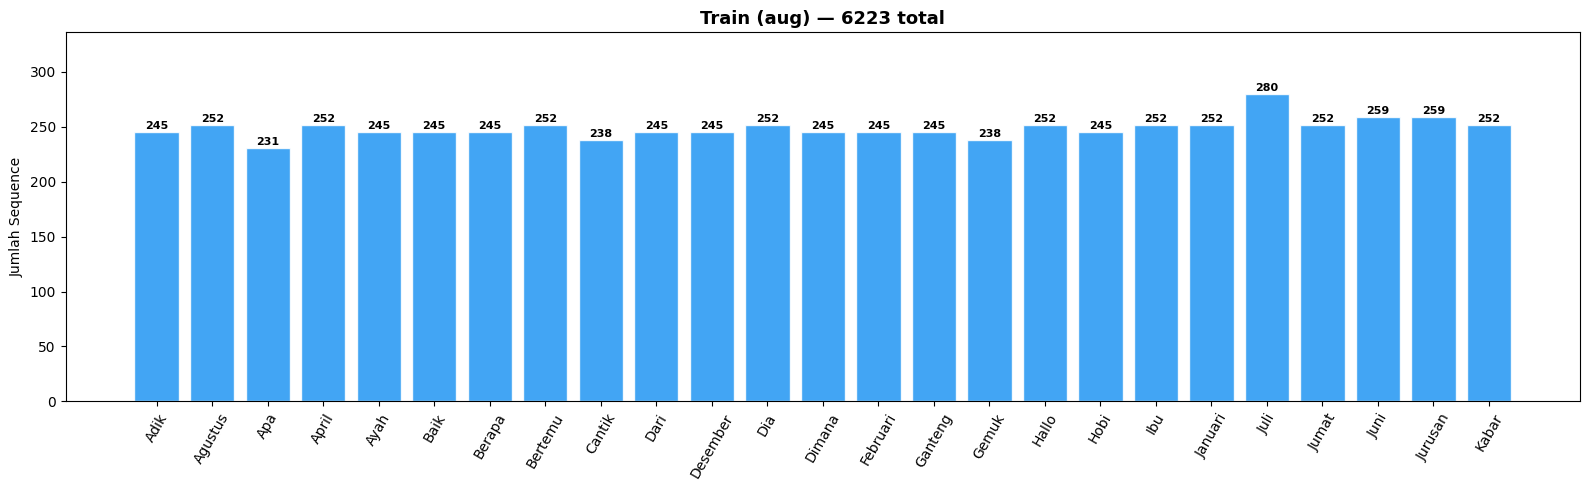

In [39]:
fig, ax = plt.subplots(figsize=(16, 5))
counts = np.sum(y_train, axis=0).astype(int)
bars = ax.bar(actions, counts, color='#2196F3', alpha=0.85, edgecolor='white')
ax.set_title(f'Train (aug) — {y_train.shape[0]} total', fontweight='bold', fontsize=13)
ax.set_ylabel('Jumlah Sequence')
ax.set_ylim(0, max(counts) * 1.2)
ax.tick_params(axis='x', rotation=60)
for bar, c in zip(bars, counts):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + max(counts)*0.01,
            str(c), ha='center', fontweight='bold', fontsize=8)
plt.tight_layout()
plt.savefig(f'{PATH_CONFIGURATION_GENERAL}/plot_distribusi_train.png', dpi=150, bbox_inches='tight')
plt.show()

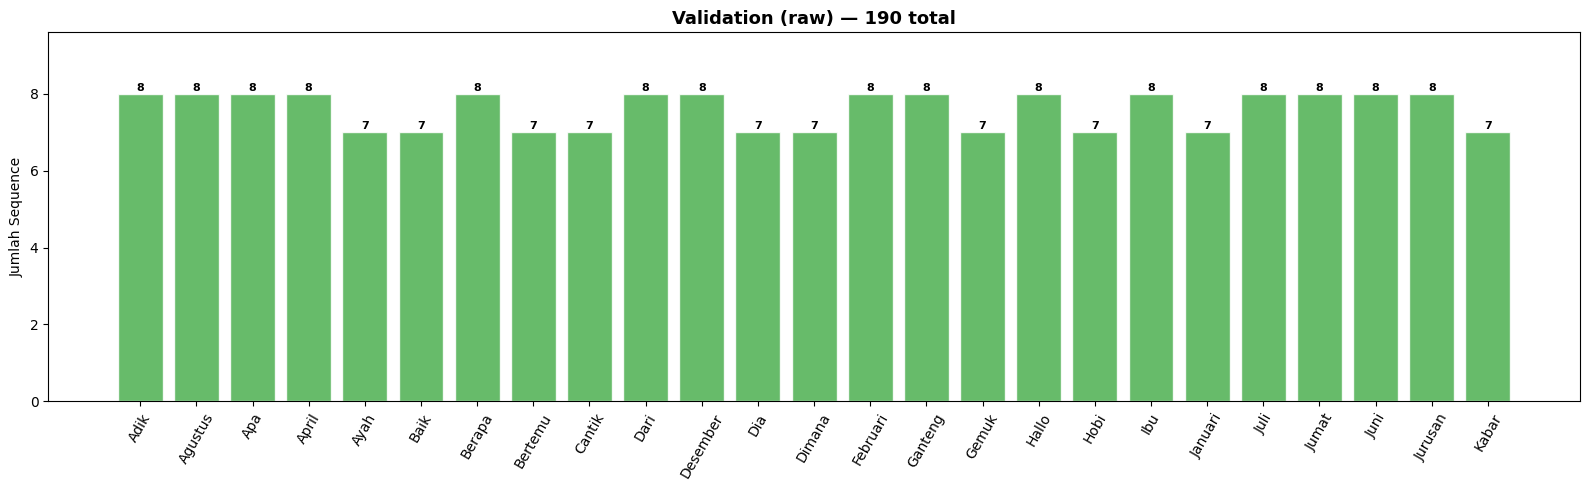

In [40]:
fig, ax = plt.subplots(figsize=(16, 5))
counts = np.sum(y_val, axis=0).astype(int)
bars = ax.bar(actions, counts, color='#4CAF50', alpha=0.85, edgecolor='white')
ax.set_title(f'Validation (raw) — {y_val.shape[0]} total', fontweight='bold', fontsize=13)
ax.set_ylabel('Jumlah Sequence')
ax.set_ylim(0, max(counts) * 1.2)
ax.tick_params(axis='x', rotation=60)
for bar, c in zip(bars, counts):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + max(counts)*0.01,
            str(c), ha='center', fontweight='bold', fontsize=8)
plt.tight_layout()
plt.savefig(f'{PATH_CONFIGURATION_GENERAL}/plot_distribusi_val.png', dpi=150, bbox_inches='tight')
plt.show()

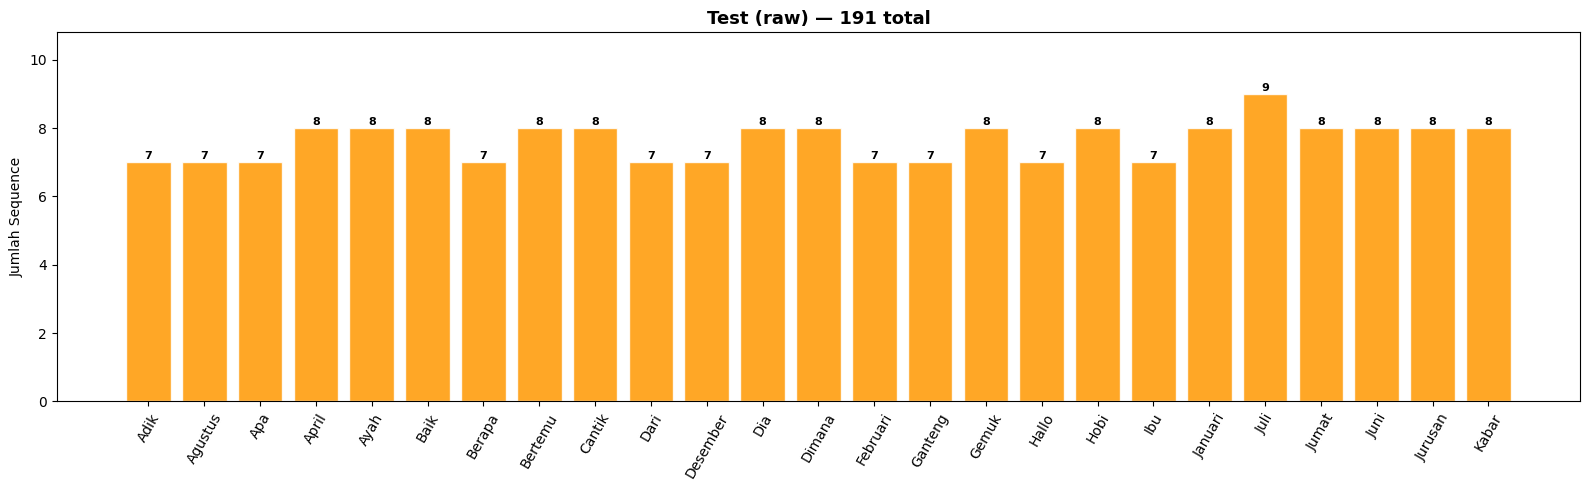

In [41]:
fig, ax = plt.subplots(figsize=(16, 5))
counts = np.sum(y_test, axis=0).astype(int)
bars = ax.bar(actions, counts, color='#FF9800', alpha=0.85, edgecolor='white')
ax.set_title(f'Test (raw) — {y_test.shape[0]} total', fontweight='bold', fontsize=13)
ax.set_ylabel('Jumlah Sequence')
ax.set_ylim(0, max(counts) * 1.2)
ax.tick_params(axis='x', rotation=60)
for bar, c in zip(bars, counts):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + max(counts)*0.01,
            str(c), ha='center', fontweight='bold', fontsize=8)
plt.tight_layout()
plt.savefig(f'{PATH_CONFIGURATION_GENERAL}/plot_distribusi_test.png', dpi=150, bbox_inches='tight')
plt.show()

In [42]:
class AttentionLayer(Layer):
    def build(self, input_shape):
        self.W = self.add_weight(shape=(input_shape[-1], 1),
                                 initializer='glorot_uniform', trainable=True)
        self.b = self.add_weight(shape=(input_shape[1], 1),
                                 initializer='zeros', trainable=True)
        super().build(input_shape)

    def call(self, x):
        e = tf.nn.tanh(tf.matmul(x, self.W) + self.b)
        a = tf.nn.softmax(e, axis=1)
        return tf.reduce_sum(x * a, axis=1)

    def get_config(self):
        return super().get_config()

@tf.keras.utils.register_keras_serializable(package='custom')
class FocalLossWithSmoothing(tf.keras.losses.Loss):
    def __init__(self, gamma=2.0, alpha=None, label_smoothing=0.05,
                 name='focal_loss_with_smoothing', **kwargs):
        super().__init__(name=name, **kwargs)
        self.gamma = gamma
        self.alpha = alpha if alpha is not None else [1.0] * 25
        self.label_smoothing = label_smoothing

    def call(self, y_true, y_pred):
        n_classes = tf.shape(y_pred)[-1]
        # Label smoothing
        y_true_smooth = y_true * (1.0 - self.label_smoothing) + \
                        self.label_smoothing / tf.cast(n_classes, tf.float32)

        y_pred = tf.clip_by_value(y_pred, 1e-7, 1.0 - 1e-7)
        ce = -y_true_smooth * tf.math.log(y_pred)

        alpha_tensor = tf.constant(self.alpha, dtype=tf.float32)
        pt = tf.reduce_sum(y_true * y_pred, axis=-1, keepdims=True)
        alpha_w = tf.reduce_sum(y_true * alpha_tensor, axis=-1, keepdims=True)
        focal_w = alpha_w * tf.pow(1.0 - pt, self.gamma)
        return tf.reduce_mean(focal_w * ce)

    def get_config(self):
        cfg = super().get_config()
        cfg.update({
            'gamma': self.gamma,
            'alpha': self.alpha,
            'label_smoothing': self.label_smoothing,
        })
        return cfg


def build_model(seq_len, n_features, n_classes):
    inputs = Input(shape=(seq_len, n_features))

    # Input noise ringan → regularisasi tambahan
    x = GaussianNoise(0.005)(inputs)

    # BiLSTM
    x = Bidirectional(LSTM(96, return_sequences=True,
                           kernel_regularizer=l2(0.001),
                           recurrent_dropout=0.0))(x)
    x = BatchNormalization()(x)
    x = Dropout(0.4)(x)

    x = Bidirectional(LSTM(64, return_sequences=True,
                           kernel_regularizer=l2(0.001),
                           recurrent_dropout=0.0))(x)
    x = BatchNormalization()(x)
    x = Dropout(0.4)(x)

    x = AttentionLayer()(x)

    # Dense
    x = Dense(192, activation='relu', kernel_regularizer=l2(0.001))(x)
    x = BatchNormalization()(x)
    x = Dropout(0.4)(x)

    x = Dense(96, activation='relu', kernel_regularizer=l2(0.001))(x)
    x = Dropout(0.3)(x)

    x = Dense(48, activation='relu', kernel_regularizer=l2(0.001))(x)
    x = Dropout(0.2)(x)

    outputs = Dense(n_classes, activation='softmax')(x)
    return Model(inputs, outputs, name='BiLSTM_Attention_SIBI_25class_v2')

FOCAL_ALPHA = [1.0] * len(actions)  # uniform, confusable-class weighting tidak dipakai untuk saat ini

model = build_model(sequence_length, FITUR_PER_FRAME, len(actions))
model.compile(
    optimizer=Adam(learning_rate=5e-4),
    loss=FocalLossWithSmoothing(gamma=2.0, alpha=FOCAL_ALPHA, label_smoothing=0.05),
    metrics=['accuracy']
)
model.summary()

with open(f'{PATH_CONFIGURATION_GENERAL}/model_summary.txt', 'w', encoding='utf-8') as f:
    model.summary(print_fn=lambda x: f.write(x + '\n'))
print("✅ Model summary tersimpan : model_summary.txt")

Model: "BiLSTM_Attention_SIBI_25class_v2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 30, 258)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gaussian_noise_2                │ (None, 30, 258)        │             0 │
│ (GaussianNoise)                 │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_4 (Bidirectional) │ (None, 30, 192)        │       272,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 30, 192)        │           768 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_10 (Dropout)            │ (None, 30, 192)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_5 (Bidirectional) │ (None, 30, 128)        │       131,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 30, 128)        │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_11 (Dropout)            │ (None, 30, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ attention_layer_2               │ (None, 128)            │           158 │
│ (AttentionLayer)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 192)            │        24,768 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_8           │ (None, 192)            │           768 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_12 (Dropout)            │ (None, 192)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 96)             │        18,528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_13 (Dropout)            │ (None, 96)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 48)             │         4,656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_14 (Dropout)            │ (None, 48)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 25)             │         1,225 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 455,607 (1.74 MB)

 Trainable params: 454,583 (1.73 MB)

 Non-trainable params: 1,024 (4.00 KB)

✅ Model summary tersimpan : model_summary.txt


In [43]:
import tensorflow as tf

checkpoint = ModelCheckpoint(
    TEMP_CHECKPOINT,
    monitor='val_loss',
    save_best_only=True,
    mode='min',
    verbose=1
)

early_stop = EarlyStopping(
    monitor='val_loss',
    patience=60,
    min_delta=1e-4,
    restore_best_weights=True,
    mode='min',
    verbose=1
)

reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=15,
    min_lr=1e-6,
    mode='min',
    verbose=1
)


class PerClassAccuracyCallback(tf.keras.callbacks.Callback):
    def __init__(self, X_val, y_val, actions, every_n=10):
        self.X_val   = X_val
        self.y_val   = y_val
        self.actions = actions
        self.every_n = every_n
        self.best_per_class = {a: 0.0 for a in actions}

    def on_epoch_end(self, epoch, logs=None):
        if (epoch + 1) % self.every_n != 0:
            return
        y_pred = np.argmax(self.model.predict(self.X_val, verbose=0), axis=1)
        y_true = np.argmax(self.y_val, axis=1)
        print(f'\n  [Epoch {epoch+1}] Per-class val accuracy:')
        for i, action in enumerate(self.actions):
            mask = (y_true == i)
            if mask.sum() == 0:
                continue
            acc_i = (y_pred[mask] == i).mean()
            if acc_i > self.best_per_class[action]:
                self.best_per_class[action] = acc_i
            flag = ' ⚠️ ' if acc_i < 0.85 else ''
            print(f'    {action:12s}: {acc_i*100:5.1f}% (best {self.best_per_class[action]*100:5.1f}%){flag}')



per_class_cb = PerClassAccuracyCallback(X_val, y_val, actions, every_n=10)

print('Memulai training...\n')
print('Catatan: training TIDAK pakai class_weight lagi → cegah double weighting')
print('         dengan focal alpha. Loss yang dipakai sudah handle imbalance.\n')

history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=N_EPOCHS,
    batch_size=64,
    callbacks=[early_stop, checkpoint, reduce_lr, per_class_cb],
    verbose=1,
    shuffle=True,
)

best_model = tf.keras.models.load_model(
    TEMP_CHECKPOINT,
    custom_objects={'AttentionLayer': AttentionLayer,
                    'FocalLossWithSmoothing': FocalLossWithSmoothing}
)

best_model.save(MODEL_OUTPUT)
best_model.save(MODEL_OUTPUT_H5)

if os.path.exists(TEMP_CHECKPOINT):
    os.remove(TEMP_CHECKPOINT)

print(f'\n✅ Model terbaik disimpan : {MODEL_OUTPUT}')
print(f'✅ Model tersimpan (.h5)    : {MODEL_OUTPUT_H5}')
print(f'   Total epoch berjalan   : {len(history.history["loss"])}')
print(f'   Val loss terbaik       : {min(history.history["val_loss"]):.4f}')
print(f'   Val accuracy terbaik   : {max(history.history["val_accuracy"])*100:.2f}%')
print(f'   Epoch terbaik (val_loss) : {np.argmin(history.history["val_loss"]) + 1}')

Memulai training...

Catatan: training TIDAK pakai class_weight lagi → cegah double weighting
         dengan focal alpha. Loss yang dipakai sudah handle imbalance.

Epoch 1/500
97/98 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step - accuracy: 0.1136 - loss: 1.3324
Epoch 1: val_loss improved from None to 0.83916, saving model to Epoch500_20260915_161659/temp_checkpoint.keras
98/98 ━━━━━━━━━━━━━━━━━━━━ 7s 42ms/step - accuracy: 0.1851 - loss: 1.1401 - val_accuracy: 0.2684 - val_loss: 0.8392 - learning_rate: 5.0000e-04
Epoch 2/500
97/98 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - accuracy: 0.3913 - loss: 0.6944
Epoch 2: val_loss improved from 0.83916 to 0.49945, saving model to Epoch500_20260915_161659/temp_checkpoint.keras
98/98 ━━━━━━━━━━━━━━━━━━━━ 4s 38ms/step - accuracy: 0.4345 - loss: 0.6042 - val_accuracy: 0.2368 - val_loss: 0.4995 - learning_rate: 5.0000e-04
Epoch 3/500
97/98 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - accuracy: 0.5346 - loss: 0.3994
Epoch 3: val_loss improved from 0.49945 to 0.31147, saving mo


✅ Model terbaik disimpan : Epoch500_20260915_161659/model25class.keras
✅ Model tersimpan (.h5)    : Epoch500_20260915_161659/model25class.h5
   Total epoch berjalan   : 293
   Val loss terbaik       : 0.0034
   Val accuracy terbaik   : 100.00%
   Epoch terbaik (val_loss) : 292


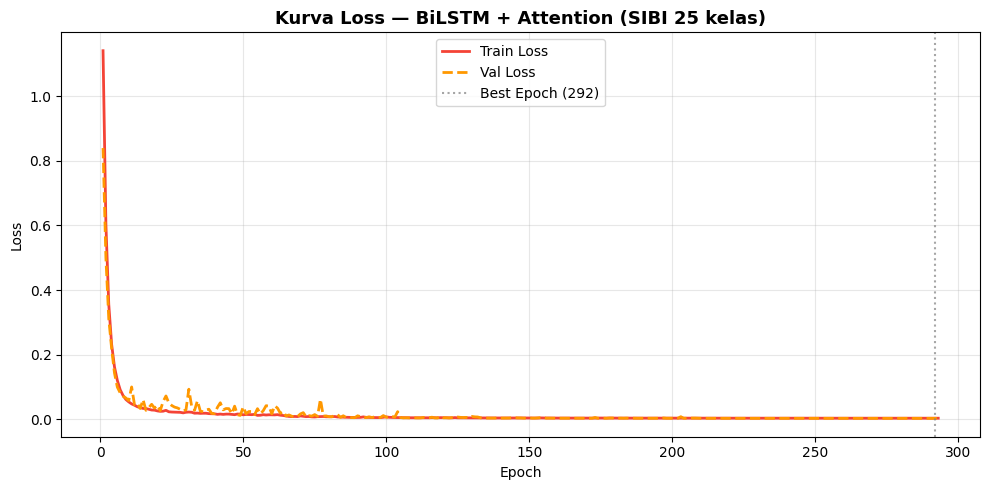

In [44]:
fig, ax = plt.subplots(figsize=(10, 5))
epochs_range = range(1, len(history.history['loss']) + 1)

ax.plot(epochs_range, history.history['loss'],
        color='#F44336', linewidth=2, label='Train Loss')
ax.plot(epochs_range, history.history['val_loss'],
        color='#FF9800', linewidth=2, linestyle='--', label='Val Loss')
best_ep = np.argmin(history.history['val_loss']) + 1
ax.axvline(x=best_ep, color='gray', linestyle=':', alpha=0.7,
           label=f'Best Epoch ({best_ep})')
ax.set_title('Kurva Loss — BiLSTM + Attention (SIBI 25 kelas)', fontsize=13, fontweight='bold')
ax.set_xlabel('Epoch'); ax.set_ylabel('Loss')
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(f'{PATH_CONFIGURATION_GENERAL}/plot_loss.png', dpi=150, bbox_inches='tight')
plt.show()

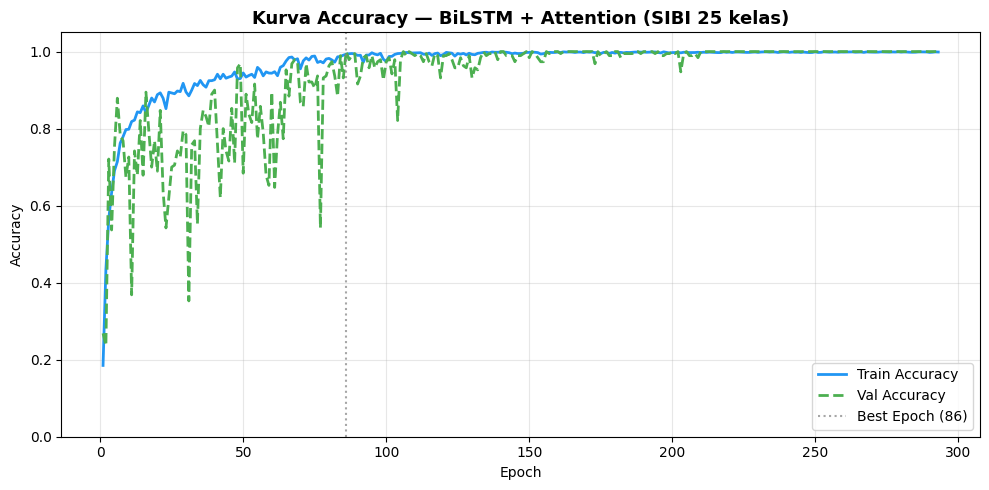

In [45]:
fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(epochs_range, history.history['accuracy'],
        color='#2196F3', linewidth=2, label='Train Accuracy')
ax.plot(epochs_range, history.history['val_accuracy'],
        color='#4CAF50', linewidth=2, linestyle='--', label='Val Accuracy')
best_ep_acc = np.argmax(history.history['val_accuracy']) + 1
ax.axvline(x=best_ep_acc, color='gray', linestyle=':', alpha=0.7,
           label=f'Best Epoch ({best_ep_acc})')
ax.set_title('Kurva Accuracy — BiLSTM + Attention (SIBI 25 kelas)', fontsize=13, fontweight='bold')
ax.set_xlabel('Epoch'); ax.set_ylabel('Accuracy'); ax.set_ylim(0, 1.05)
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(f'{PATH_CONFIGURATION_GENERAL}/plot_accuracy.png', dpi=150, bbox_inches='tight')
plt.show()

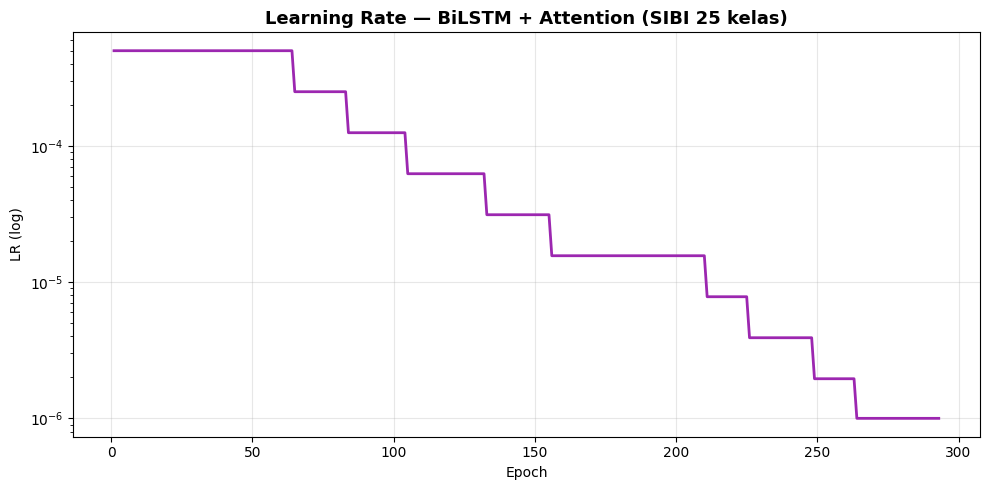

In [46]:
fig, ax = plt.subplots(figsize=(10, 5))

if 'learning_rate' in history.history:
    ax.plot(epochs_range, history.history['learning_rate'],
            color='#9C27B0', linewidth=2)
    ax.set_yscale('log')
    ax.set_title('Learning Rate — BiLSTM + Attention (SIBI 25 kelas)', fontsize=13, fontweight='bold')
    ax.set_xlabel('Epoch'); ax.set_ylabel('LR (log)')
    ax.grid(alpha=0.3)
else:
    ax.text(0.5, 0.5, 'LR history\ntidak tersedia',
            ha='center', va='center', transform=ax.transAxes)
    ax.set_title('Learning Rate', fontsize=13, fontweight='bold')

plt.tight_layout()
plt.savefig(f'{PATH_CONFIGURATION_GENERAL}/plot_learning_rate.png', dpi=150, bbox_inches='tight')
plt.show()

In [47]:
loss, acc = best_model.evaluate(X_test, y_test, verbose=0)
print('=' * 50)
print(f'  TEST ACCURACY : {acc * 100:.2f}%')
print(f'  TEST LOSS     : {loss:.4f}')
print('=' * 50)

y_pred_prob = best_model.predict(X_test, verbose=0)
y_pred      = np.argmax(y_pred_prob, axis=1)
y_true      = np.argmax(y_test,      axis=1)

print('\nClassification Report:')
print(classification_report(y_true, y_pred, target_names=actions))

report_str = classification_report(y_true, y_pred, target_names=actions)
with open(f'{PATH_CONFIGURATION_GENERAL}/classification_report.txt', 'w') as f:
    f.write(f"Test Accuracy : {acc*100:.2f}%\n")
    f.write(f"Test Loss     : {loss:.4f}\n\n")
    f.write(report_str)
print("✅ Classification report tersimpan")

  TEST ACCURACY : 98.95%
  TEST LOSS     : 0.0040

Classification Report:
              precision    recall  f1-score   support

        Adik       1.00      1.00      1.00         7
     Agustus       1.00      1.00      1.00         7
         Apa       1.00      1.00      1.00         7
       April       1.00      1.00      1.00         8
        Ayah       1.00      1.00      1.00         8
        Baik       1.00      1.00      1.00         8
      Berapa       1.00      1.00      1.00         7
     Bertemu       1.00      1.00      1.00         8
      Cantik       0.89      1.00      0.94         8
        Dari       1.00      1.00      1.00         7
    Desember       1.00      1.00      1.00         7
         Dia       1.00      1.00      1.00         8
      Dimana       1.00      1.00      1.00         8
    Februari       0.88      1.00      0.93         7
     Ganteng       1.00      0.86      0.92         7
       Gemuk       1.00      1.00      1.00         8
       

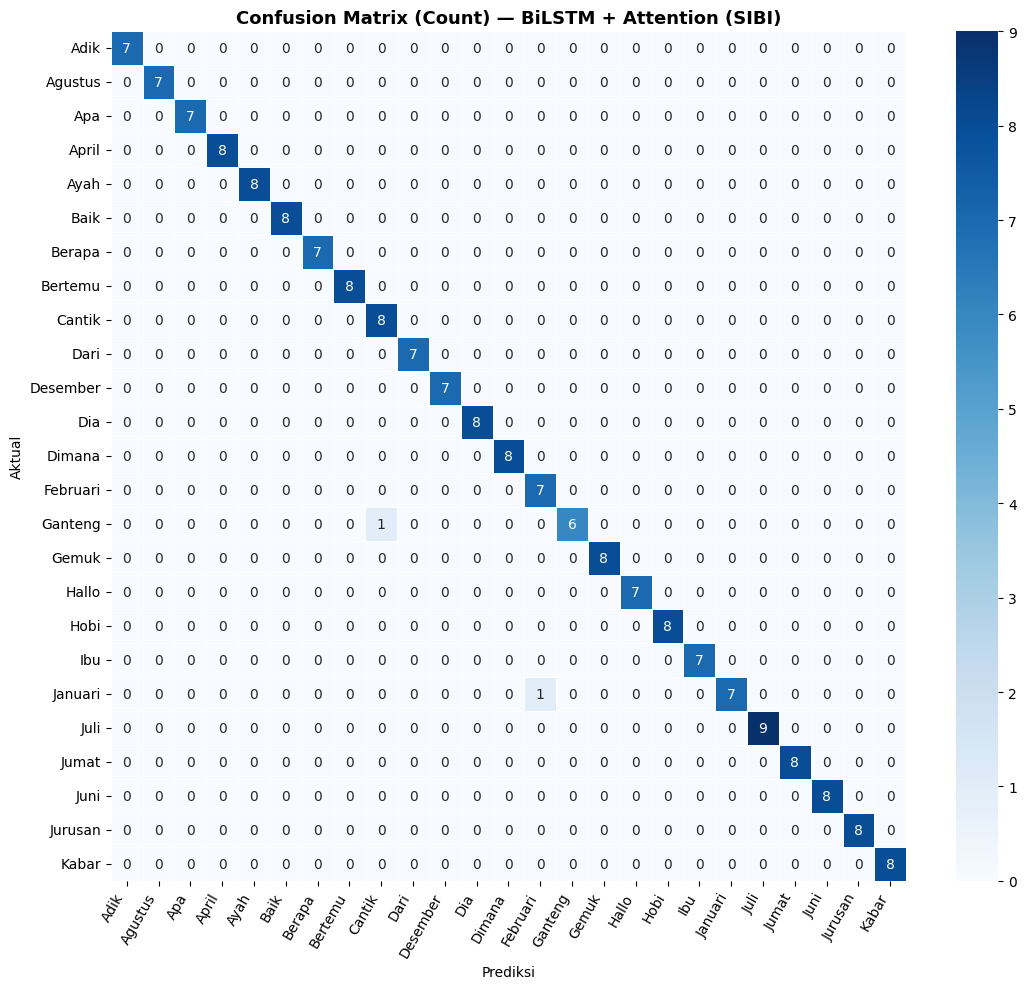

In [48]:
cm = confusion_matrix(y_true, y_pred)

fig, ax = plt.subplots(figsize=(max(10, len(actions) * 0.45), max(8, len(actions) * 0.4)))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=actions, yticklabels=actions, ax=ax,
            linewidths=0.5, linecolor='white')
ax.set_title('Confusion Matrix (Count) — BiLSTM + Attention (SIBI)', fontweight='bold', fontsize=13)
ax.set_xlabel('Prediksi'); ax.set_ylabel('Aktual')
plt.xticks(rotation=60, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig(f'{PATH_CONFIGURATION_GENERAL}/plot_confusion_matrix_count.png', dpi=150, bbox_inches='tight')
plt.show()

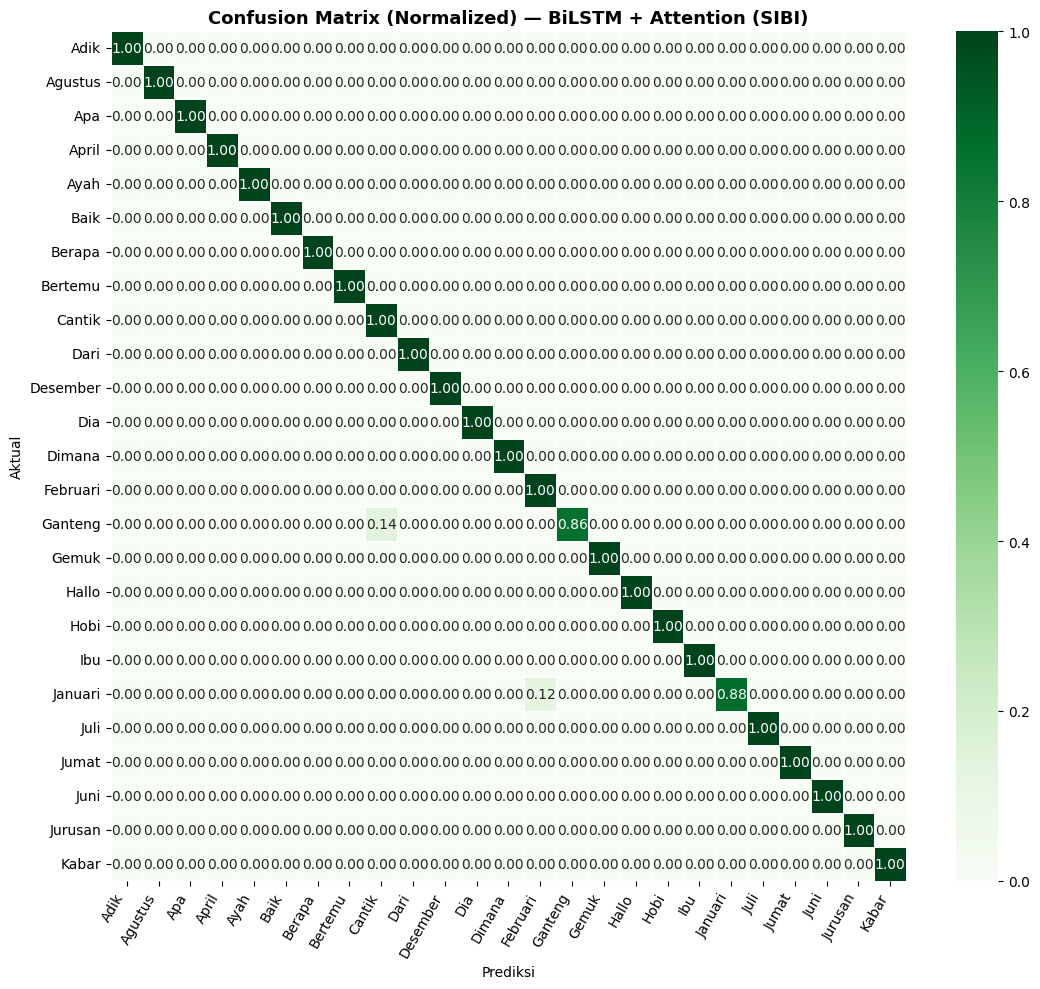

In [49]:
cm_norm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]

fig, ax = plt.subplots(figsize=(max(10, len(actions) * 0.45), max(8, len(actions) * 0.4)))
sns.heatmap(cm_norm, annot=True, fmt='.2f', cmap='Greens',
            xticklabels=actions, yticklabels=actions, ax=ax,
            linewidths=0.5, linecolor='white', vmin=0, vmax=1)
ax.set_title('Confusion Matrix (Normalized) — BiLSTM + Attention (SIBI)', fontweight='bold', fontsize=13)
ax.set_xlabel('Prediksi'); ax.set_ylabel('Aktual')
plt.xticks(rotation=60, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig(f'{PATH_CONFIGURATION_GENERAL}/plot_confusion_matrix_normalized.png', dpi=150, bbox_inches='tight')
plt.show()

In [50]:
print('\n⚠️  Confusable Pairs:')
for i in range(len(actions)):
    for j in range(len(actions)):
        if i != j and cm[i][j] > 0:
            print(f'  {actions[i]} → diprediksi {actions[j]}: {cm[i][j]} kali')


⚠️  Confusable Pairs:
  Ganteng → diprediksi Cantik: 1 kali
  Januari → diprediksi Februari: 1 kali


In [51]:
report    = classification_report(y_true, y_pred,
                                   target_names=actions, output_dict=True)
df_report = pd.DataFrame(report).transpose().loc[actions]

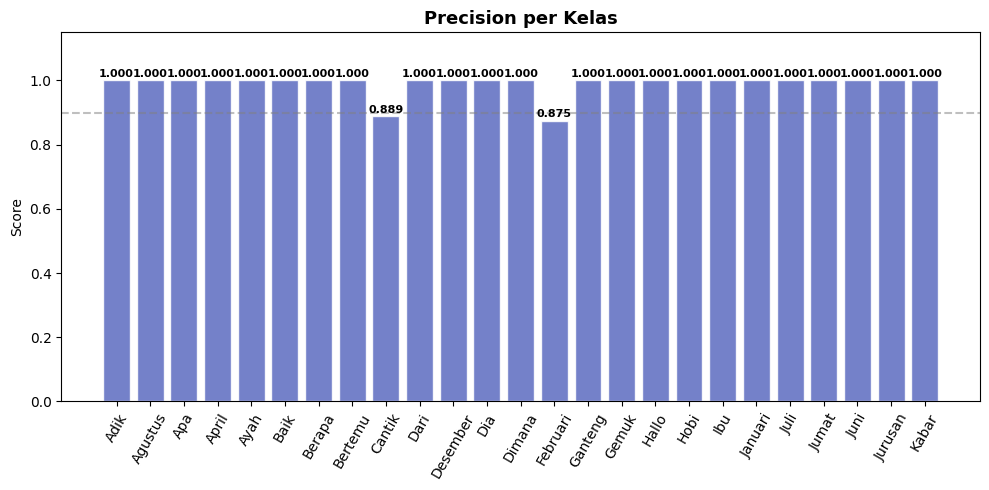

In [52]:
fig, ax = plt.subplots(figsize=(max(10, len(actions) * 0.35), 5))
vals = df_report['precision'].values
bars = ax.bar(actions, vals, color='#5C6BC0', alpha=0.85, edgecolor='white')
ax.set_title('Precision per Kelas', fontweight='bold', fontsize=13)
ax.set_ylim(0, 1.15); ax.set_ylabel('Score')
ax.axhline(y=0.9, color='gray', linestyle='--', alpha=0.5)
ax.tick_params(axis='x', rotation=60)
for bar, v in zip(bars, vals):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
            f'{v:.3f}', ha='center', fontweight='bold', fontsize=8)
plt.tight_layout()
plt.savefig(f'{PATH_CONFIGURATION_GENERAL}/plot_precision.png', dpi=150, bbox_inches='tight')
plt.show()

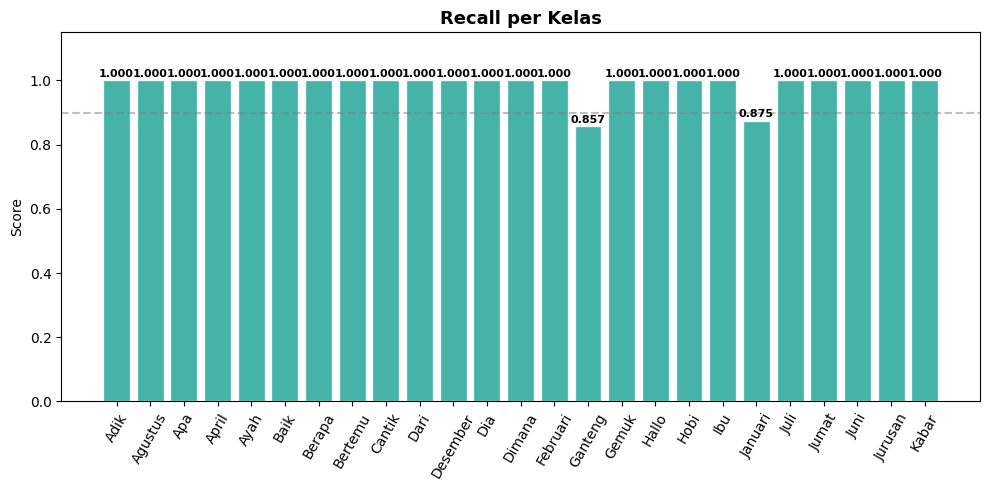

In [53]:
fig, ax = plt.subplots(figsize=(max(10, len(actions) * 0.35), 5))
vals = df_report['recall'].values
bars = ax.bar(actions, vals, color='#26A69A', alpha=0.85, edgecolor='white')
ax.set_title('Recall per Kelas', fontweight='bold', fontsize=13)
ax.set_ylim(0, 1.15); ax.set_ylabel('Score')
ax.axhline(y=0.9, color='gray', linestyle='--', alpha=0.5)
ax.tick_params(axis='x', rotation=60)
for bar, v in zip(bars, vals):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
            f'{v:.3f}', ha='center', fontweight='bold', fontsize=8)
plt.tight_layout()
plt.savefig(f'{PATH_CONFIGURATION_GENERAL}/plot_recall.png', dpi=150, bbox_inches='tight')
plt.show()

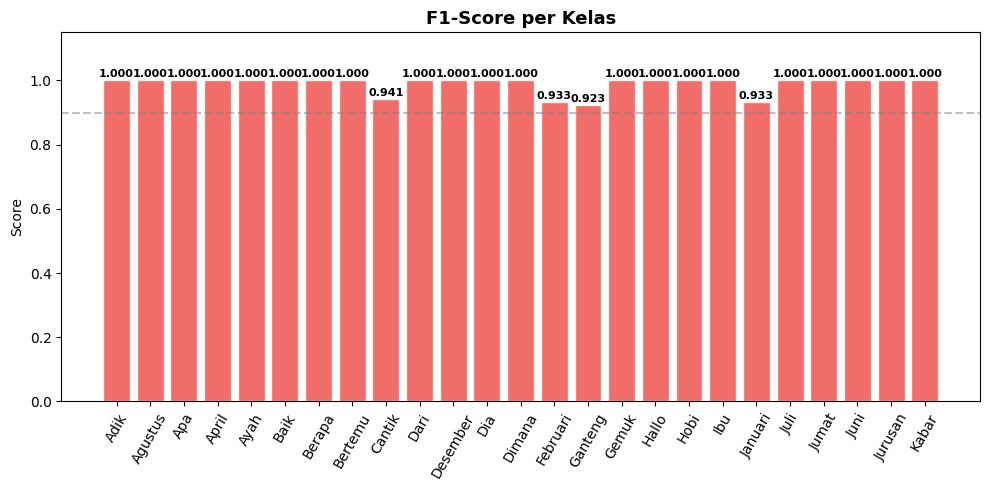

In [54]:
fig, ax = plt.subplots(figsize=(max(10, len(actions) * 0.35), 5))
vals = df_report['f1-score'].values
bars = ax.bar(actions, vals, color='#EF5350', alpha=0.85, edgecolor='white')
ax.set_title('F1-Score per Kelas', fontweight='bold', fontsize=13)
ax.set_ylim(0, 1.15); ax.set_ylabel('Score')
ax.axhline(y=0.9, color='gray', linestyle='--', alpha=0.5)
ax.tick_params(axis='x', rotation=60)
for bar, v in zip(bars, vals):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
            f'{v:.3f}', ha='center', fontweight='bold', fontsize=8)
plt.tight_layout()
plt.savefig(f'{PATH_CONFIGURATION_GENERAL}/plot_f1score.png', dpi=150, bbox_inches='tight')
plt.show()

In [55]:
print(df_report[['precision','recall','f1-score','support']].to_string())

          precision    recall  f1-score  support
Adik       1.000000  1.000000  1.000000      7.0
Agustus    1.000000  1.000000  1.000000      7.0
Apa        1.000000  1.000000  1.000000      7.0
April      1.000000  1.000000  1.000000      8.0
Ayah       1.000000  1.000000  1.000000      8.0
Baik       1.000000  1.000000  1.000000      8.0
Berapa     1.000000  1.000000  1.000000      7.0
Bertemu    1.000000  1.000000  1.000000      8.0
Cantik     0.888889  1.000000  0.941176      8.0
Dari       1.000000  1.000000  1.000000      7.0
Desember   1.000000  1.000000  1.000000      7.0
Dia        1.000000  1.000000  1.000000      8.0
Dimana     1.000000  1.000000  1.000000      8.0
Februari   0.875000  1.000000  0.933333      7.0
Ganteng    1.000000  0.857143  0.923077      7.0
Gemuk      1.000000  1.000000  1.000000      8.0
Hallo      1.000000  1.000000  1.000000      7.0
Hobi       1.000000  1.000000  1.000000      8.0
Ibu        1.000000  1.000000  1.000000      7.0
Januari    1.000000 

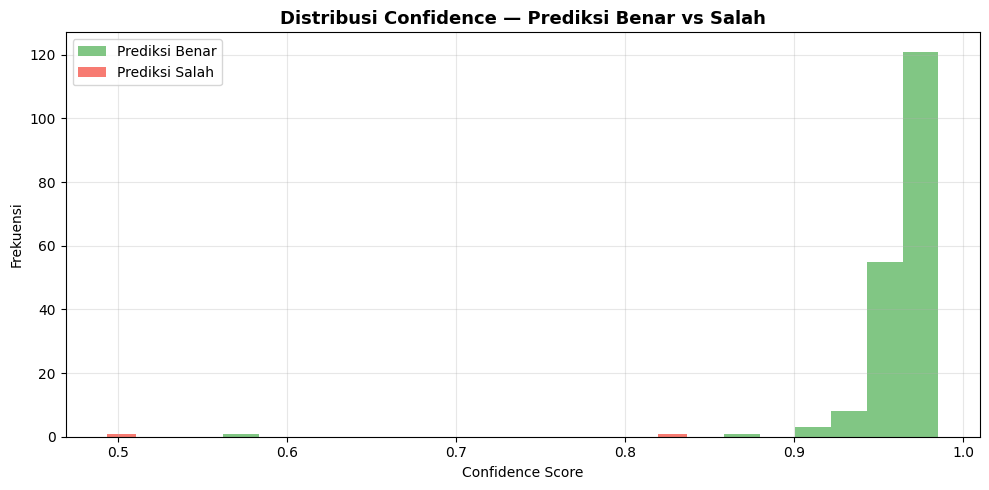

Confidence rata-rata benar : 0.9641
Confidence rata-rata salah : 0.6652


In [56]:
max_conf   = np.max(y_pred_prob, axis=1)
is_correct = (y_pred == y_true)

fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(max_conf[is_correct],  bins=20, alpha=0.7,
        color='#4CAF50', label='Prediksi Benar')
ax.hist(max_conf[~is_correct], bins=20, alpha=0.7,
        color='#F44336', label='Prediksi Salah')
ax.set_title('Distribusi Confidence — Prediksi Benar vs Salah', fontweight='bold', fontsize=13)
ax.set_xlabel('Confidence Score'); ax.set_ylabel('Frekuensi')
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(f'{PATH_CONFIGURATION_GENERAL}/plot_confidence_histogram.png', dpi=150, bbox_inches='tight')
plt.show()

print(f'Confidence rata-rata benar : {max_conf[is_correct].mean():.4f}')
print(f'Confidence rata-rata salah : {max_conf[~is_correct].mean():.4f}')

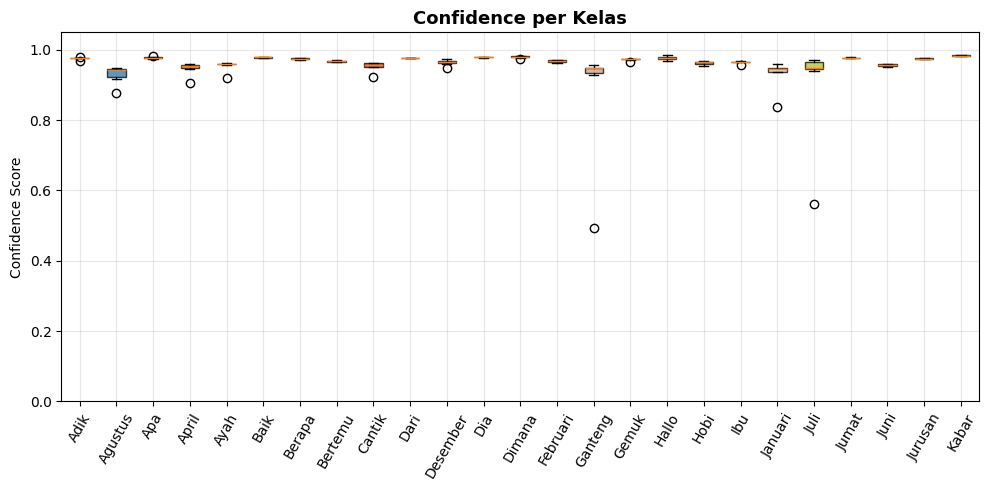

In [57]:
fig, ax = plt.subplots(figsize=(max(10, len(actions) * 0.4), 5))
bp = ax.boxplot(
    [max_conf[y_true == i] for i in range(len(actions))],
    labels=actions, patch_artist=True
)

# generate warna sebanyak jumlah kelas (bukan list tetap 11 warna)
colors_cycle = plt.cm.tab20(np.linspace(0, 1, len(actions)))
for patch, c in zip(bp['boxes'], colors_cycle):
    patch.set_facecolor(c); patch.set_alpha(0.75)

ax.set_title('Confidence per Kelas', fontweight='bold', fontsize=13)
ax.set_ylabel('Confidence Score'); ax.set_ylim(0, 1.05); ax.grid(alpha=0.3)
ax.tick_params(axis='x', rotation=60)
plt.tight_layout()
plt.savefig(f'{PATH_CONFIGURATION_GENERAL}/plot_confidence_per_class.png', dpi=150, bbox_inches='tight')
plt.show()

In [58]:
report_full = classification_report(
    y_true, y_pred, target_names=actions, output_dict=True
)

print('=' * 60)
print('        RINGKASAN HASIL TRAINING — SIBI 25 KELAS (v2)')
print('=' * 60)
print(f'  Arsitektur    : BiLSTM + Attention + Focal Loss + Label Smoothing')
print(f'  Kelas         : {", ".join(actions)}')
print(f'  Total data    : {X.shape[0]} (asli) → train diaugmentasi')
print(f'  Fitur/frame   : {FITUR_PER_FRAME}')
print(f'  Sequence len  : {sequence_length} frame @ 30fps = {sequence_length/30:.1f} detik')
print('-' * 60)
print(f'  Train (aug) / Val / Test : {X_train.shape[0]} / {X_val.shape[0]} / {X_test.shape[0]}')
print('-' * 60)
print(f'  Test Accuracy : {acc * 100:.2f}%')
print(f'  Test Loss     : {loss:.4f}')
print(f'  Macro F1      : {report_full["macro avg"]["f1-score"]:.4f}')
print(f'  Weighted F1   : {report_full["weighted avg"]["f1-score"]:.4f}')
print('-' * 60)
print('  Per-Class:')
for action in actions:
    r = report_full[action]
    print(f'  {action:12s}  P={r["precision"]:.3f}  '
          f'R={r["recall"]:.3f}  F1={r["f1-score"]:.3f}')
print('=' * 60)
print(f'\n✅ Output model  : {MODEL_OUTPUT}')

with open(f'{PATH_CONFIGURATION_GENERAL}/ringkasan_training.txt', 'w', encoding='utf-8') as f:
    f.write('=' * 60 + '\n')
    f.write('        RINGKASAN HASIL TRAINING — SIBI 25 KELAS (v2)\n')
    f.write('=' * 60 + '\n')
    f.write(f'  Arsitektur    : BiLSTM + Attention + Focal Loss + Label Smoothing\n')
    f.write(f'  Kelas         : {", ".join(actions)}\n')
    f.write(f'  Jumlah Kelas  : {len(actions)}\n')
    f.write(f'  Total data    : {X.shape[0]} (asli) → train diaugmentasi\n')
    f.write(f'  Fitur/frame   : {FITUR_PER_FRAME}\n')
    f.write(f'  Sequence len  : {sequence_length} frame @ 30fps = {sequence_length/30:.1f} detik\n')
    f.write('-' * 60 + '\n')
    f.write(f'  Train (aug) / Val / Test : {X_train.shape[0]} / {X_val.shape[0]} / {X_test.shape[0]}\n')
    f.write('-' * 60 + '\n')
    f.write(f'  Test Accuracy : {acc * 100:.2f}%\n')
    f.write(f'  Test Loss     : {loss:.4f}\n')
    f.write(f'  Macro F1      : {report_full["macro avg"]["f1-score"]:.4f}\n')
    f.write(f'  Weighted F1   : {report_full["weighted avg"]["f1-score"]:.4f}\n')
    f.write(f'  Macro P       : {report_full["macro avg"]["precision"]:.4f}\n')
    f.write(f'  Macro R       : {report_full["macro avg"]["recall"]:.4f}\n')
    f.write('-' * 60 + '\n')
    f.write(f'  Epoch terbaik (val_accuracy) : {np.argmax(history.history["val_accuracy"]) + 1}\n')
    f.write(f'  Epoch terbaik (val_loss)     : {np.argmin(history.history["val_loss"]) + 1}\n')
    f.write(f'  Total epoch berjalan         : {len(history.history["loss"])}\n')
    f.write(f'  Val Accuracy terbaik         : {max(history.history["val_accuracy"]) * 100:.2f}%\n')
    f.write(f'  Val Loss terbaik             : {min(history.history["val_loss"]):.4f}\n')
    f.write('-' * 60 + '\n')
    f.write('  Per-Class Metrics:\n')
    f.write(f'  {"Kelas":<14} {"Precision":>10} {"Recall":>10} {"F1-Score":>10} {"Support":>10}\n')
    f.write('  ' + '-' * 50 + '\n')
    for action in actions:
        r = report_full[action]
        f.write(f'  {action:<14} {r["precision"]:>10.4f} {r["recall"]:>10.4f} '
                f'{r["f1-score"]:>10.4f} {int(r["support"]):>10}\n')
    f.write('-' * 60 + '\n')
    f.write('=' * 60 + '\n')

print('✅ Ringkasan tersimpan : ringkasan_training.txt')

        RINGKASAN HASIL TRAINING — SIBI 25 KELAS (v2)
  Arsitektur    : BiLSTM + Attention + Focal Loss + Label Smoothing
  Kelas         : Adik, Agustus, Apa, April, Ayah, Baik, Berapa, Bertemu, Cantik, Dari, Desember, Dia, Dimana, Februari, Ganteng, Gemuk, Hallo, Hobi, Ibu, Januari, Juli, Jumat, Juni, Jurusan, Kabar
  Total data    : 1270 (asli) → train diaugmentasi
  Fitur/frame   : 258
  Sequence len  : 30 frame @ 30fps = 1.0 detik
------------------------------------------------------------
  Train (aug) / Val / Test : 6223 / 190 / 191
------------------------------------------------------------
  Test Accuracy : 98.95%
  Test Loss     : 0.0040
  Macro F1      : 0.9892
  Weighted F1   : 0.9895
------------------------------------------------------------
  Per-Class:
  Adik          P=1.000  R=1.000  F1=1.000
  Agustus       P=1.000  R=1.000  F1=1.000
  Apa           P=1.000  R=1.000  F1=1.000
  April         P=1.000  R=1.000  F1=1.000
  Ayah          P=1.000  R=1.000  F1=1.000
  B